In [1]:
import pandas as pd

df = pd.read_csv("/content/simulated_household_energy_20000.csv")
print(df.shape)
df.head()

(20000, 18)


,household_id,house_size,sqft,occupants,owns_PhoneCharging,owns_Radio,owns_TV,owns_IronBox,owns_ElectricKettle,owns_Fridge,owns_Microwave,owns_WashingMachine,owns_Laptop,owns_DeepFreezer,owns_Fan,owns_WaterHeater,monthly_consumption_kwh,monthly_bill_kes
0,H00001,2 Beds,857.0,5,1,1,1,1,1,1,1,0,0,0.0,0,0,164.34,4139
1,H00002,3+ Beds,1219.0,6,0,0,1,1,0,1,0,0,1,0.0,1,0,182.28,4640
2,H00003,2 Beds,892.0,4,1,1,1,1,0,0,0,0,1,0.0,1,0,97.47,2278
3,H00004,1 Bed,629.0,3,1,1,1,1,0,0,1,0,0,0.0,0,1,124.06,3013
4,H00005,1 Bed,676.0,2,1,0,0,1,1,1,0,0,0,0.0,0,1,117.53,2831


In [2]:
# Blank deep-freezer values: treat as "does not own" (about 90% of homes don't)
df["owns_DeepFreezer"] = df["owns_DeepFreezer"].fillna(0).astype(int)

# Drop columns the model should not use
df = df.drop(columns=["household_id", "sqft", "monthly_bill_kes"])

print(df.isnull().sum().sum())   # should print 0
print(df.shape)

0
(20000, 15)


In [3]:
from sklearn.model_selection import train_test_split

# Turn house_size text into 0/1 columns the model can read
X = pd.get_dummies(df.drop(columns=["monthly_consumption_kwh"]),
                   columns=["house_size"], dtype=int)
y = df["monthly_consumption_kwh"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)
print(list(X.columns))

(16000, 17) (4000, 17)
['occupants', 'owns_PhoneCharging', 'owns_Radio', 'owns_TV', 'owns_IronBox', 'owns_ElectricKettle', 'owns_Fridge', 'owns_Microwave', 'owns_WashingMachine', 'owns_Laptop', 'owns_DeepFreezer', 'owns_Fan', 'owns_WaterHeater', 'house_size_1 Bed', 'house_size_2 Beds', 'house_size_3+ Beds', 'house_size_Studio']


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                           random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE (kWh)": round(mean_absolute_error(y_test, pred), 2),
        "R2": round(r2_score(y_test, pred), 4),
    })

pd.DataFrame(results).sort_values("MAE (kWh)")

,Model,MAE (kWh),R2
0,Linear Regression,11.42,0.8842
2,Gradient Boosting,11.57,0.8806
1,Random Forest,11.99,0.8721


In [5]:
best = models["Linear Regression"]

weights = pd.Series(best.coef_, index=X.columns).sort_values(ascending=False)
print("Base:", round(best.intercept_, 2))
weights.round(2)

Base: 30.95


,0
owns_DeepFreezer,57.06
owns_WaterHeater,44.44
owns_Fridge,42.79
house_size_3+ Beds,14.85
owns_TV,12.16
owns_Laptop,9.44
owns_ElectricKettle,9.29
owns_Microwave,9.25
occupants,8.75
owns_IronBox,8.74


In [7]:
import joblib

joblib.dump(best, "energy_model.joblib")
joblib.dump(list(X.columns), "model_columns.joblib")

['model_columns.joblib']

In [10]:
# GENERATE PREDICTIONS

pred = best.predict(X_test)

In [11]:
# EVALUATION METRICS

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

# Predictions
pred = best.predict(X_test)

# Metrics
mae = mean_absolute_error(y_test, pred)
mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred)

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MAE  : 11.4184
MSE  : 223.2286
RMSE : 14.9408
R²   : 0.8842


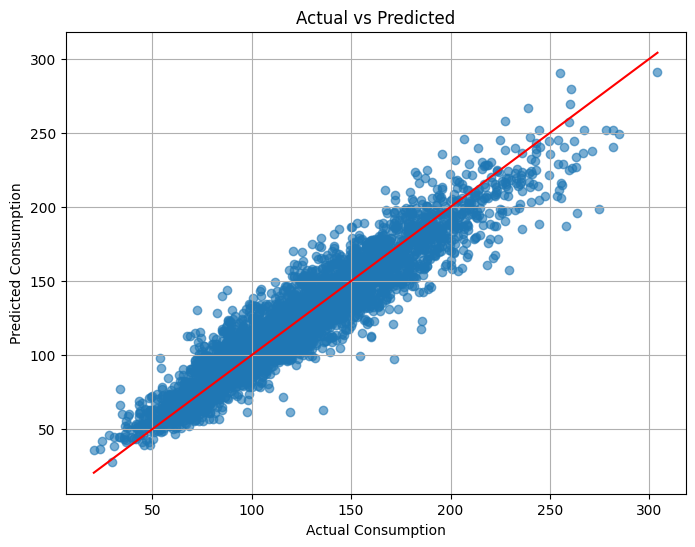

In [12]:
# ACTUAL VS PREDICTED

import matplotlib.pyplot as plt

pred = best.predict(X_test)

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    pred,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel("Actual Consumption")
plt.ylabel("Predicted Consumption")
plt.title("Actual vs Predicted")

plt.grid(True)
plt.show()

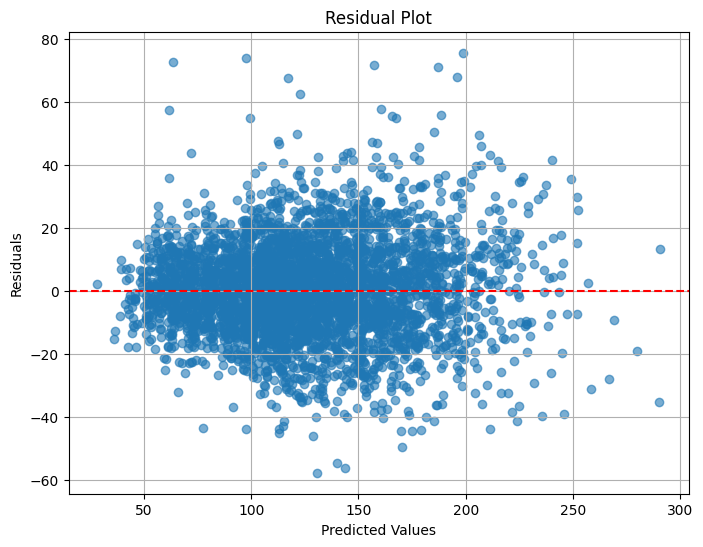

In [13]:
# RESIDUAL ANALYSIS

pred = best.predict(X_test)

residuals = y_test - pred

plt.figure(figsize=(8,6))

plt.scatter(
    pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.grid(True)
plt.show()

In [14]:
# CROSS VALIDATION


from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    best,
    X,
    y,
    cv=5,
    scoring='r2'
)

print("Fold Scores:")
print(cv_scores)

print("\nAverage R²:")
print(cv_scores.mean())

print("\nStandard Deviation:")
print(cv_scores.std())

Fold Scores:
[0.88617871 0.88452047 0.88197128 0.88664917 0.87869249]

Average R²:
0.8836024231654391

Standard Deviation:
0.002950620503145242


house_size_Studio     -12.521422
house_size_1 Bed       -6.040648
owns_PhoneCharging     -0.738815
owns_Radio              1.483723
house_size_2 Beds       3.711015
owns_Fan                6.126766
owns_WashingMachine     6.893800
owns_IronBox            8.741491
occupants               8.754784
owns_Microwave          9.247816
owns_ElectricKettle     9.286601
owns_Laptop             9.444169
owns_TV                12.160039
house_size_3+ Beds     14.851056
owns_Fridge            42.785156
owns_WaterHeater       44.441291
owns_DeepFreezer       57.063855
dtype: float64


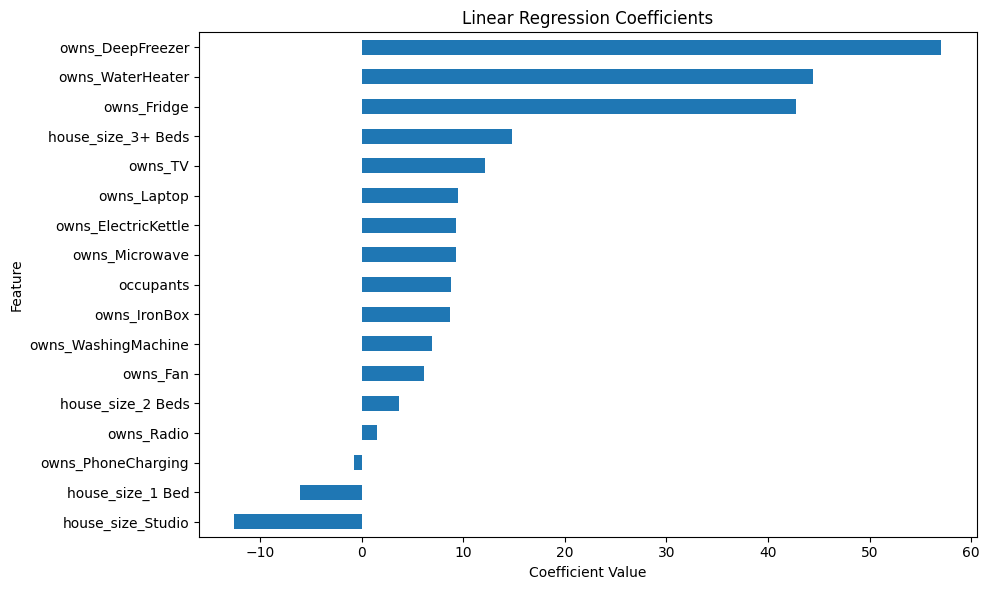

In [15]:
# COEFFICIENT ANALYSIS


import pandas as pd

weights = pd.Series(
    best.coef_,
    index=X.columns
).sort_values()

print(weights)

plt.figure(figsize=(10,6))

weights.plot(kind='barh')

plt.title("Linear Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [16]:
# EXPLAIN A SINGLE PREDICTION

sample = X_test.iloc[0]

contributions = pd.Series(
    sample.values * best.coef_,
    index=X.columns
)

contributions = contributions.sort_values(
    ascending=False
)

print("Top Positive Contributors")
print(contributions.head(10))

print("\nTop Negative Contributors")
print(contributions.tail(10))

Top Positive Contributors
owns_WaterHeater       44.441291
occupants              35.019135
house_size_3+ Beds     14.851056
owns_TV                12.160039
owns_IronBox            8.741491
owns_Radio              1.483723
owns_Fridge             0.000000
owns_Microwave          0.000000
owns_ElectricKettle     0.000000
owns_Fan                0.000000
dtype: float64

Top Negative Contributors
owns_Microwave         0.000000
owns_ElectricKettle    0.000000
owns_Fan               0.000000
owns_WashingMachine    0.000000
owns_DeepFreezer       0.000000
owns_Laptop            0.000000
house_size_2 Beds      0.000000
house_size_1 Bed      -0.000000
house_size_Studio     -0.000000
owns_PhoneCharging    -0.738815
dtype: float64
